# Data set creation
---

In [2]:
import pandas as pd
import numpy as np
meta_df = pd.read_csv("data/processed_data/YACHIDA_CRC_2019/metadata.tsv", sep="\t")
MGX_df = pd.read_csv("data/processed_data/YACHIDA_CRC_2019/species.tsv", sep="\t")
MTB_df = pd.read_csv("data/processed_data/YACHIDA_CRC_2019/mtb.tsv", sep="\t")


In [3]:
print(meta_df.columns)
print(meta_df.shape)
print(meta_df['Study.Group'].value_counts(dropna=False))

Index(['Dataset', 'Sample', 'Subject', 'Study.Group', 'Age', 'Age.Units',
       'Gender', 'BMI', 'DOI', 'Publication.Name', 'Stage', 'Brinkman Index',
       'Alcohol', 'Tumor location', 'Shared.w.ERAWIJANTARI_2020'],
      dtype='object')
(347, 15)
Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
HS               30
Stage_0          27
Name: count, dtype: int64


In [4]:
# Merging the healthy samples, 'HS' and 'Healthy' in meta_data

meta_df['Study.Group'] = meta_df['Study.Group'].replace({'HS': 'Healthy'})
print(meta_df['Study.Group'].value_counts(dropna=False))


Study.Group
Healthy         157
Stage_I_II       69
Stage_III_IV     54
MP               40
Stage_0          27
Name: count, dtype: int64


In [5]:
# Setting sample as index

def set_sample_index(df):
    df = df.copy()
    if "Sample" in df.columns:
        df = df.set_index("Sample")
    df.index = df.index.astype(str).str.strip()
    return df

meta_df = set_sample_index(meta_df)
MGX_df = set_sample_index(MGX_df)
MTB_df = set_sample_index(MTB_df)

In [6]:
# Applying Center Log Ration tarnsformation to MGX and Log10 transformation

def apply_CLR(abundance_df):
  min_nonzero = abundance_df[abundance_df > 0].min().min()
  pseudo_count = min_nonzero / 2 #check miultiplying different values 0.3 - 0.7
  df_no_zero = abundance_df + pseudo_count

  geom_mean = np.exp(np.log(df_no_zero).mean(axis=1))

  clr_df = np.log(df_no_zero.div(geom_mean, axis = 0))
  return clr_df



MGX_transformed = apply_CLR(MGX_df)
MTB_transformed = np.log10(MTB_df + 1)


In [7]:
# Creating Binary field for diseased in metadata

diseased_df = meta_df.copy()
diseased_df['target'] = (diseased_df['Study.Group'] != 'Healthy').astype(int)

diseased_df = set_sample_index(diseased_df)

# Alinging X and Y
common_samples = (
    diseased_df.index.intersection(MGX_transformed.index).intersection(MTB_transformed.index)
)
MGX_df_diseased = MGX_transformed.loc[common_samples]
MTB_df_diseased = MTB_transformed.loc[common_samples]

y_diseased = diseased_df.loc[common_samples, "target"]

print(f"X_mtb shape: {MTB_df_diseased.shape}")
print(f"X_mgx shape: {MGX_df_diseased.shape}") 
print(f"y shape: {y_diseased.shape}") 
print(f"Target distribution:\n{y_diseased.value_counts()}")


X_mtb shape: (347, 450)
X_mgx shape: (347, 57702)
y shape: (347,)
Target distribution:
target
1    190
0    157
Name: count, dtype: int64


In [8]:
# Creating Binary field for MP classification in metadata

stage_MP_df = meta_df[meta_df['Study.Group'].isin(['Healthy', 'MP'])].copy()
stage_MP_df['target'] = (stage_MP_df['Study.Group'] == 'MP').astype(int)

# Alinging X and Y
common_samples = (
    stage_MP_df.index.intersection(MGX_transformed.index).intersection(MTB_transformed.index)
)
MGX_df_MP = MGX_transformed.loc[common_samples]
MTB_df_MP = MTB_transformed.loc[common_samples]

y_MP = stage_MP_df['target']

print(f"X_mtb shape: {MTB_df_MP.shape}")
print(f"X_mgx shape: {MGX_df_MP.shape}") 
print(f"y shape: {y_MP.shape}") 
print(f"Target distribution:\n{y_MP.value_counts()}")


X_mtb shape: (197, 450)
X_mgx shape: (197, 57702)
y shape: (197,)
Target distribution:
target
0    157
1     40
Name: count, dtype: int64


In [9]:
# Creating Binary field for early stage in metadata

stage_0_df = meta_df[meta_df['Study.Group'].isin(['Healthy', 'Stage_0'])].copy()
stage_0_df['target'] = (stage_0_df['Study.Group'] == 'Stage_0').astype(int)

# Alinging X and Y
common_samples = (
    stage_0_df.index.intersection(MGX_transformed.index).intersection(MTB_transformed.index)
)
MGX_df_early = MGX_transformed.loc[common_samples]
MTB_df_early = MTB_transformed.loc[common_samples]

y_early = stage_0_df['target']

print(f"X_mtb shape: {MTB_df_early.shape}")
print(f"X_mgx shape: {MGX_df_early.shape}") 
print(f"y shape: {y_early.shape}") 
print(f"Target distribution:\n{y_early.value_counts()}")


X_mtb shape: (184, 450)
X_mgx shape: (184, 57702)
y shape: (184,)
Target distribution:
target
0    157
1     27
Name: count, dtype: int64


In [10]:
# Creating Binary field for intermediate stage in metadata

stage_I_II_df = meta_df[meta_df['Study.Group'].isin(['Healthy', 'Stage_I_II'])].copy()
stage_I_II_df['target'] = (stage_I_II_df['Study.Group'] == 'Stage_I_II').astype(int)

# Alinging X and Y
common_samples = (
    stage_I_II_df.index.intersection(MGX_transformed.index).intersection(MTB_transformed.index)
)
MGX_df_intermediate = MGX_transformed.loc[common_samples]
MTB_df_intermediate = MTB_transformed.loc[common_samples]

y_intermediate = stage_I_II_df['target']

print(f"X_mtb shape: {MTB_df_intermediate.shape}")
print(f"X_mgx shape: {MGX_df_intermediate.shape}") 
print(f"y shape: {y_intermediate.shape}") 
print(f"Target distribution:\n{y_intermediate.value_counts()}")


X_mtb shape: (226, 450)
X_mgx shape: (226, 57702)
y shape: (226,)
Target distribution:
target
0    157
1     69
Name: count, dtype: int64


In [11]:
# Creating Binary field for intermediate stage in metadata

Stage_III_IV_df = meta_df[meta_df['Study.Group'].isin(['Healthy', 'Stage_III_IV'])].copy()
Stage_III_IV_df['target'] = (Stage_III_IV_df['Study.Group'] == 'Stage_III_IV').astype(int)

# Alinging X and Y
common_samples = (
    Stage_III_IV_df.index.intersection(MGX_transformed.index).intersection(MTB_transformed.index)
)
MGX_df_late = MGX_transformed.loc[common_samples]
MTB_df_late = MTB_transformed.loc[common_samples]

y_late = Stage_III_IV_df['target']

print(f"X_mtb shape: {MTB_df_late.shape}")
print(f"X_mgx shape: {MGX_df_late.shape}") 
print(f"y shape: {y_late.shape}") 
print(f"Target distribution:\n{y_late.value_counts()}")


X_mtb shape: (211, 450)
X_mgx shape: (211, 57702)
y shape: (211,)
Target distribution:
target
0    157
1     54
Name: count, dtype: int64


In [12]:
# Exporting binary data sets
import os

folder_path = r"C:\Users\tonyp\compSci\Research\Multimodal_Microbiome_Fusion_Project\Meta_Fusion\data\processed_data\YACHIDA_CRC_2019\Binary_datasets"
os.makedirs(folder_path, exist_ok=True)

# Diseased
MGX_df_diseased.to_csv(
    os.path.join(folder_path, "MGX_df_diseased.tsv"), sep="\t"
)
MTB_df_diseased.to_csv(
    os.path.join(folder_path, "MTB_df_diseased.tsv"), sep="\t"
)
y_diseased.to_csv(os.path.join(folder_path, "y_diseased.tsv"), sep="\t")

# MP
MGX_df_MP.to_csv(
    os.path.join(folder_path, "MGX_df_MP.tsv"), sep="\t"
)
MTB_df_MP.to_csv(
    os.path.join(folder_path, "MTB_df_MP.tsv"), sep="\t"
)
y_MP.to_csv(os.path.join(folder_path, "y_MP.tsv"), sep="\t")

# Early
MGX_df_early.to_csv(
    os.path.join(folder_path, "MGX_df_early.tsv"), sep="\t"
)
MTB_df_early.to_csv(
    os.path.join(folder_path, "MTB_df_early.tsv"), sep="\t"
)
y_early.to_csv(os.path.join(folder_path, "y_early.tsv"), sep="\t")

# Intermediate
MGX_df_intermediate.to_csv(
    os.path.join(folder_path, "MGX_df_intermediate.tsv"), sep="\t"
)
MTB_df_intermediate.to_csv(
    os.path.join(folder_path, "MTB_df_intermediate.tsv"), sep="\t"
)
y_intermediate.to_csv(os.path.join(folder_path, "y_intermediate.tsv"), sep="\t")

# Late
MGX_df_late.to_csv(
    os.path.join(folder_path, "MGX_df_late.tsv"), sep="\t"
)
MTB_df_late.to_csv(
    os.path.join(folder_path, "MTB_df_late.tsv"), sep="\t"
)
y_late.to_csv(os.path.join(folder_path, "y_late.tsv"), sep="\t")

--- MGX PCA ---
PC1 Variance: 9.89% | PC2 Variacnce : 5.49%
Top 10 PCs Cumulative Variance: 31.83%

--- Metabolomics (MTB) PCA ---
PC1 Variance: 9.26% | PC2 Variance: 5.08%
Top 10 PCs Cumulative Variance: 33.04%



C:\Users\tonyp\AppData\Local\Temp\ipykernel_5568\1618750583.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pca_MGX_df["target"] = y_diseased.values
C:\Users\tonyp\AppData\Local\Temp\ipykernel_5568\1618750583.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pca_MTB_df["target"] = y_diseased.values


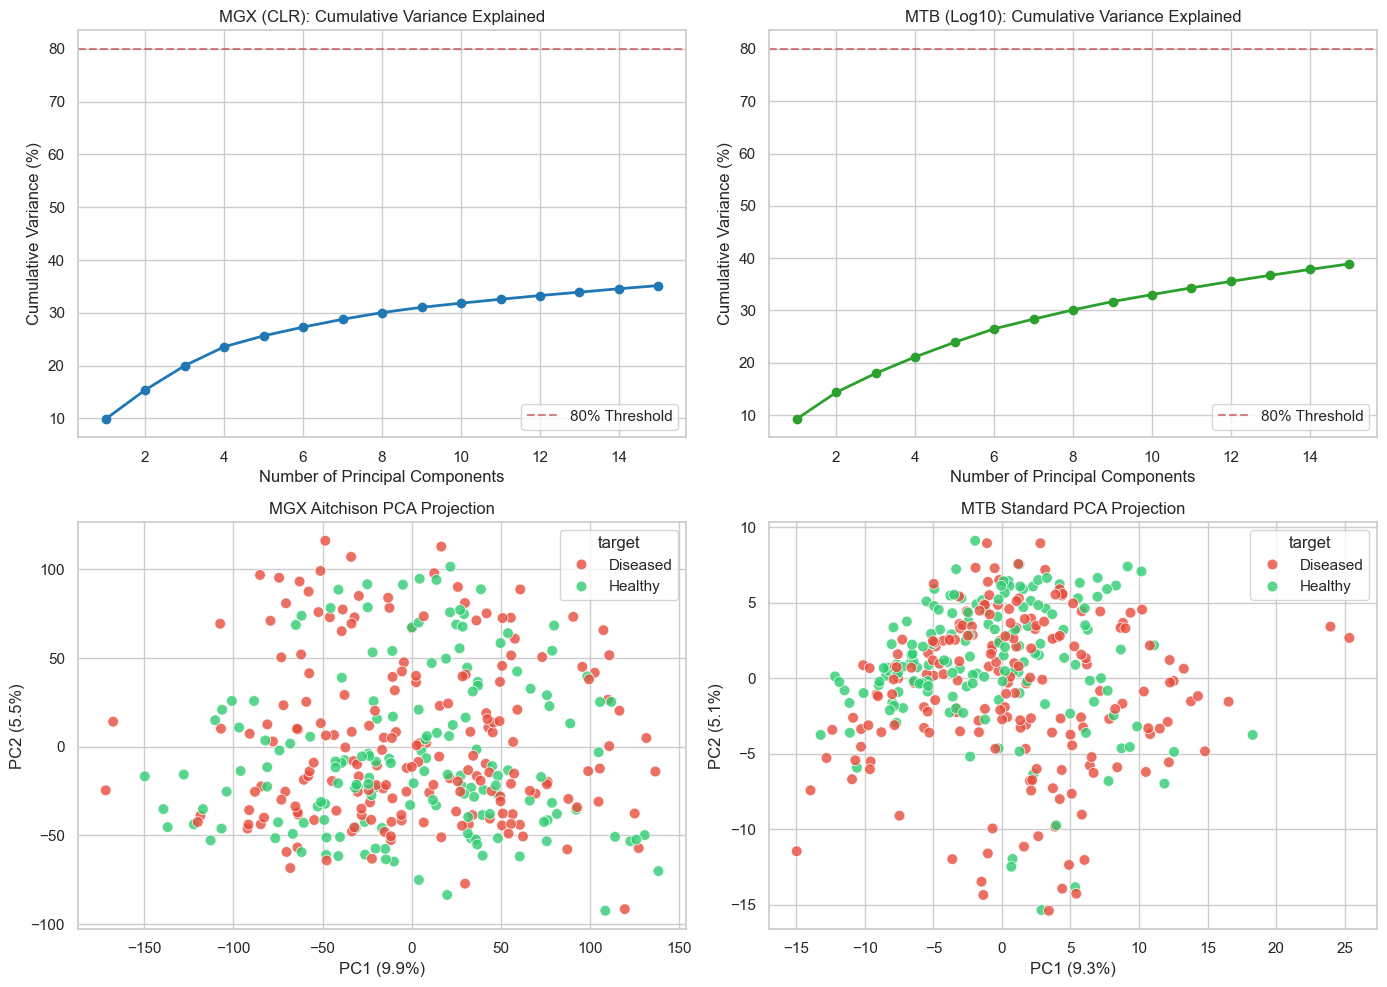

In [13]:
# Principle Component Analysis for diseased
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns

#Style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# MGX fit
pca_MGX = PCA(n_components=min(MGX_transformed.shape[0], MGX_transformed.shape[1]))
pcs_MGX = pca_MGX.fit_transform(MGX_transformed)
pca_MGX_df = pd.DataFrame (pcs_MGX, index = MGX_transformed.index, columns = [f"PC{i+1}" for i in range(pcs_MGX.shape[1])])

# MTB fit
scaled_MTB = StandardScaler().fit_transform(MTB_transformed)
pca_MTB =  PCA(n_components=min(scaled_MTB.shape[0], scaled_MTB.shape[1]))
pcs_MTB = pca_MTB.fit_transform(scaled_MTB)
pca_MTB_df = pd.DataFrame(pcs_MTB, index = MTB_transformed.index, columns = [f"PC{i+1}" for i in range(pcs_MTB.shape[1])])

var_MGX = pca_MGX.explained_variance_ratio_ * 100
var_MTB = pca_MTB.explained_variance_ratio_ * 100

print(f"--- MGX PCA ---")
print(f"PC1 Variance: {var_MGX[0]:.2f}% | PC2 Variacnce : {var_MGX[1]:.2f}%")
print(f"Top 10 PCs Cumulative Variance: {np.sum(var_MGX[:10]):.2f}%\n")

print(f"--- Metabolomics (MTB) PCA ---")
print(f"PC1 Variance: {var_MTB[0]:.2f}% | PC2 Variance: {var_MTB[1]:.2f}%")
print(f"Top 10 PCs Cumulative Variance: {np.sum(var_MTB[:10]):.2f}%\n")

# Visuals

status_labels = y_diseased.map({0: "Healthy", 1: "Diseased"})
fig, axes = plt.subplots(2, 2, figsize=(14, 10))


#Ensure float values
pca_MGX_df = pca_MGX_df.astype({"PC1": float, "PC2": float})
pca_MTB_df = pca_MTB_df.astype({"PC1": float, "PC2": float})

# append target column to garuntee index alignment
pca_MGX_df["target"] = y_diseased.values
pca_MTB_df["target"] = y_diseased.values

# --- Plot 1: MGX Scree Plot ---
axes[0, 0].plot(range(1, 16), np.cumsum(var_MGX[:15]), 'o-', color='#1f77b4', linewidth=2)
axes[0, 0].set_title("MGX (CLR): Cumulative Variance Explained")
axes[0, 0].set_xlabel("Number of Principal Components")
axes[0, 0].set_ylabel("Cumulative Variance (%)")
axes[0, 0].axhline(y=80, color='r', linestyle='--', alpha=0.7, label='80% Threshold')
axes[0, 0].legend()

# --- Plot 2: MTB Scree Plot ---
axes[0, 1].plot(range(1, 16), np.cumsum(var_MTB[:15]), 'o-', color='#2ca02c', linewidth=2)
axes[0, 1].set_title("MTB (Log10): Cumulative Variance Explained")
axes[0, 1].set_xlabel("Number of Principal Components")
axes[0, 1].set_ylabel("Cumulative Variance (%)")
axes[0, 1].axhline(y=80, color='r', linestyle='--', alpha=0.7, label='80% Threshold')
axes[0, 1].legend()

# --- Plot 3: MGX 2D Projection ---
sns.scatterplot(
    data=pca_MGX_df,
    x="PC1",
    y="PC2",
    hue=status_labels,
    ax=axes[1, 0],
    palette={"Healthy": "#2ecc71", "Diseased": "#e74c3c"},
    s=60,
    alpha=0.8,
)
axes[1, 0].set_title("MGX Aitchison PCA Projection")
axes[1, 0].set_xlabel(f"PC1 ({var_MGX[0]:.1f}%)")
axes[1, 0].set_ylabel(f"PC2 ({var_MGX[1]:.1f}%)")

# --- Plot 4: MTB 2D Projection ---
sns.scatterplot(
    data=pca_MTB_df,
    x="PC1",
    y="PC2",
    hue=status_labels,
    ax=axes[1, 1],
    palette={"Healthy": "#2ecc71", "Diseased": "#e74c3c"},
    s=60,
    alpha=0.8,
)
axes[1, 1].set_title("MTB Standard PCA Projection")
axes[1, 1].set_xlabel(f"PC1 ({var_MTB[0]:.1f}%)")
axes[1, 1].set_ylabel(f"PC2 ({var_MTB[1]:.1f}%)")

plt.tight_layout()
plt.show()


# Logistic Regression Model

In [ ]:
# single omic classifier for healthy vs diseased
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

X_mgx = MGX_df_diseased
X_mtb = MTB_df_diseased

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=63)

mgx_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10,
penalty='l1', solver='liblinear', class_weight='balanced', cv=cv, scoring='roc_auc', random_state=63, max_iter=1000,),)

mtb_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=20,
 penalty='l1', solver='liblinear', class_weight='balanced', cv=cv, scoring='roc_auc', random_state=63, max_iter=1000,),)

mgx_model.fit(X_mgx, y_diseased)
mtb_model.fit(X_mtb, y_diseased)

mgx_scores_matrix = mgx_model.named_steps['logisticregressioncv'].scores_[1]
best_auc_mgx = mgx_scores_matrix.mean(axis=0).max()

mtb_scores_matrix = mtb_model.named_steps['logisticregressioncv'].scores_[1]
best_auc_mtb = mtb_scores_matrix.mean(axis=0).max()

print(f"Mean Cross-Validated AUC (MGX): {best_auc_mgx:.4f}")    
print(f"Mean Cross-Validated AUC (MTB): {best_auc_mtb:.4f}")

c:\Users\tonyp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 347 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=347 when initializing the masker.


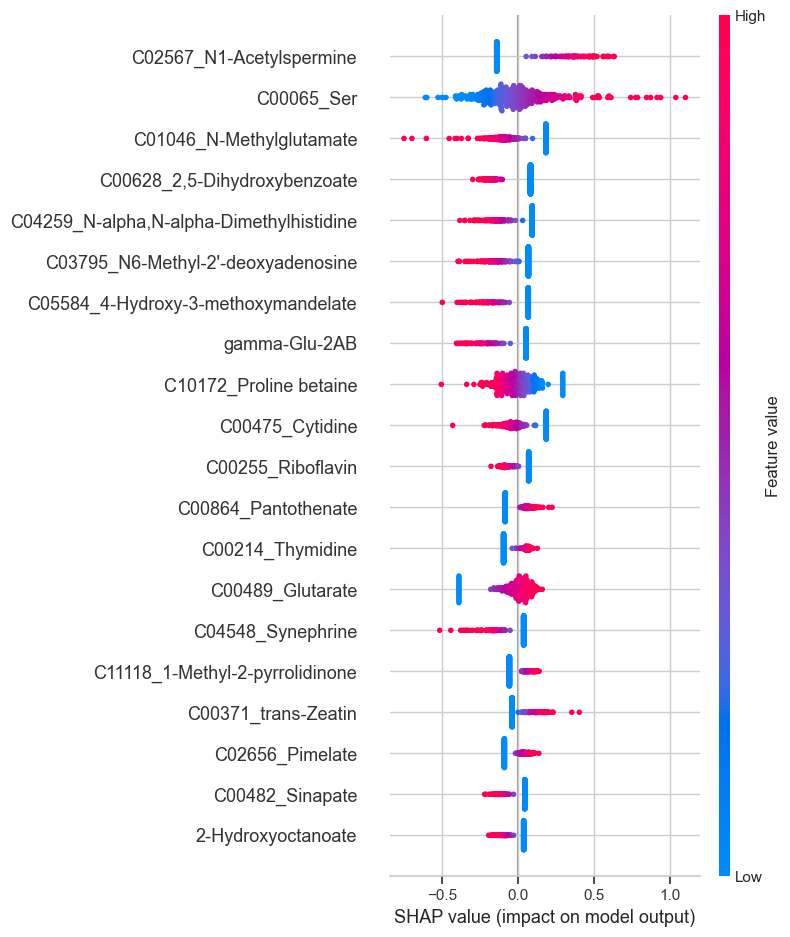

In [ ]:
import shap

#SHAP MTB for healthy vs diseased
mtb_scaler = mtb_model.named_steps['standardscaler']
mtb_log_reg = mtb_model.named_steps['logisticregressioncv']
mtb_X_scaled = mtb_scaler.transform(X_mtb)
            
explainer = shap.LinearExplainer(mtb_log_reg, mtb_X_scaled)
shap_values_mtb = explainer(mtb_X_scaled)
shap_values_mtb.feature_names = list(X_mtb.columns)

shap.summary_plot(shap_values_mtb, mtb_X_scaled, feature_names=X_mtb.columns)


Background dataset has 347 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=347 when initializing the masker.
c:\Users\tonyp\AppData\Local\Programs\Python\Python312\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


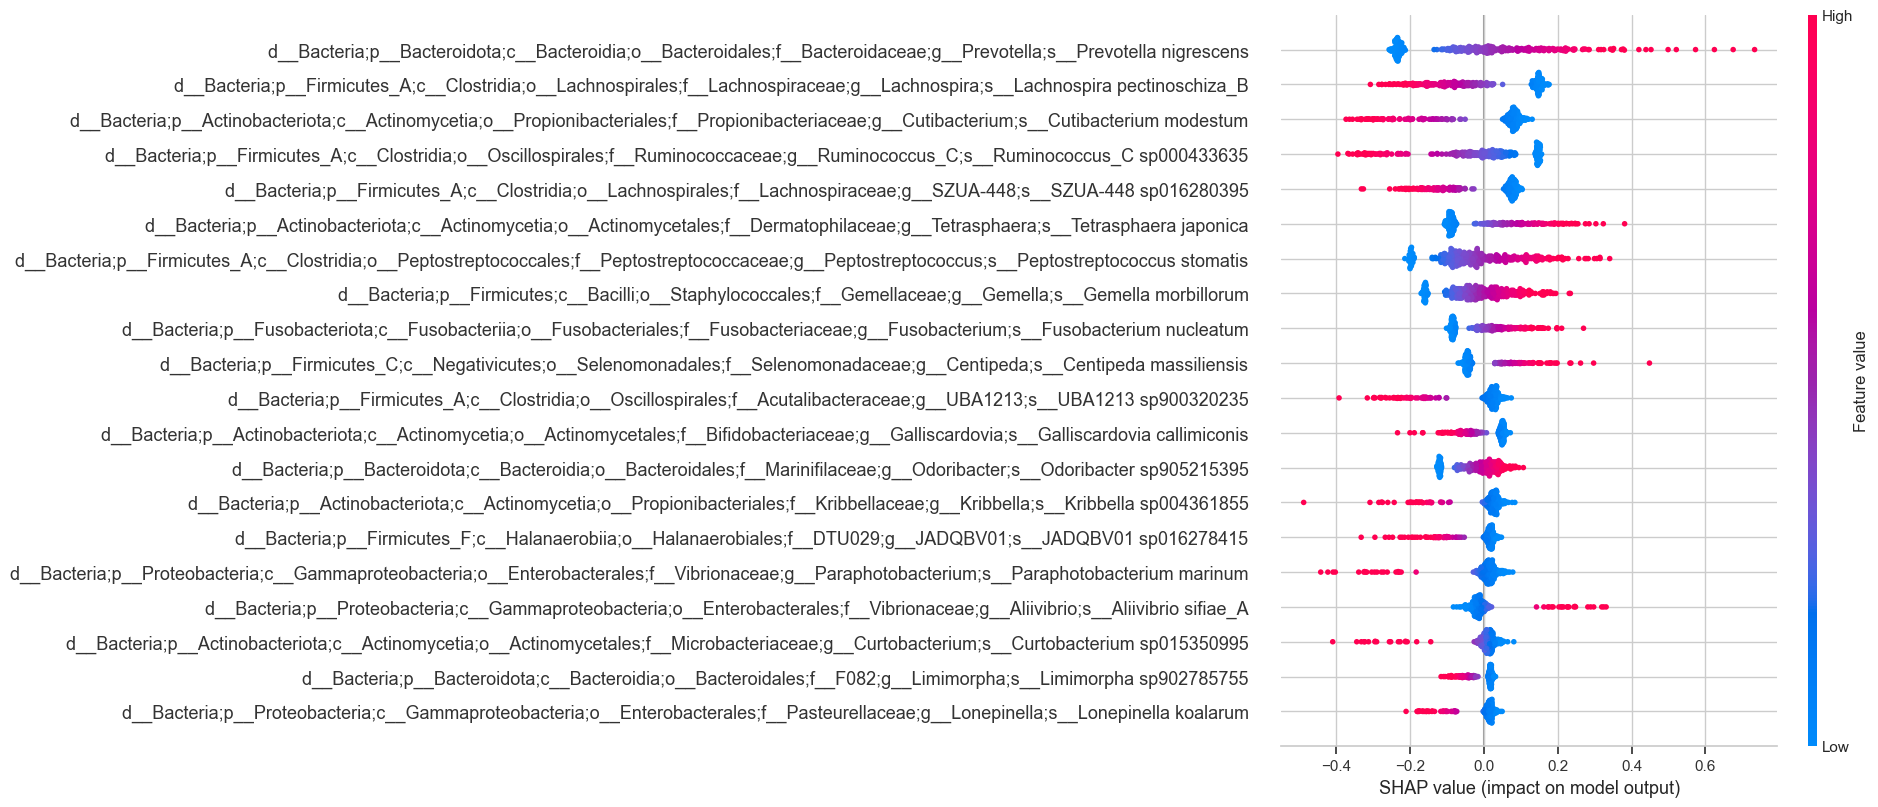

In [ ]:

# SHAP MGX for healthy vs diseased
mgx_scaler = mgx_model.named_steps['standardscaler']
mgx_log_reg = mgx_model.named_steps['logisticregressioncv']
X_mgx_scaled = mgx_scaler.transform(X_mgx)

explainer_mgx = shap.LinearExplainer(mgx_log_reg, X_mgx_scaled)
shap_values_mgx = explainer_mgx(X_mgx_scaled)
shap_values_mgx.feature_names = list(X_mgx.columns)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_mgx,
    X_mgx_scaled,
    feature_names=X_mgx.columns,
    max_display=20,
    show=True,
)